# День 08. Упражнение 00 
# Бинарный классификатор. Логистическая регрессия

## 0. Импорты

In [98]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

## 1. Предобработка

- Получи данные из файла [`checker-timestamp.csv`](https://drive.google.com/file/d/1pooM4cITtG249msX3GK_6W0eEiblzAf5/view?usp=sharing).

In [99]:
df = pd.read_csv("../data/checker_timestamp.csv")

- Создай датафрейм `df` со столбцами: `date`, `am`, `pm`, `target`, где `date` — это дата дня, `am` — количество коммитов за день до полудня (integer), `pm` — количество коммитов за день после полудня (integer), `target` — weekend/working_day.

In [100]:
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df = df.dropna()
print(df.head(2))

                   timestamp
0 2020-04-17 05:19:02.744528
1 2020-04-17 05:22:35.249331


In [101]:
df["date"] = df["timestamp"].dt.date
df["hour"] = df["timestamp"].dt.hour
print(df.head(2))

                   timestamp        date  hour
0 2020-04-17 05:19:02.744528  2020-04-17     5
1 2020-04-17 05:22:35.249331  2020-04-17     5


In [102]:
df["daytime"] = pd.cut(
    df["hour"], bins=[0, 11, 23], labels=["am", "pm"], include_lowest=True
)
df.head(2)

,timestamp,date,hour,daytime
0,2020-04-17 05:19:02.744528,2020-04-17,5,am
1,2020-04-17 05:22:35.249331,2020-04-17,5,am


In [103]:
df["target"] = np.where(df["timestamp"].dt.weekday > 4, "weekend", "working_day")
df = df.drop(columns=["timestamp", "hour"])
df.head(2)

,date,daytime,target
0,2020-04-17,am,working_day
1,2020-04-17,am,working_day


In [104]:
df = df.groupby(["date", "daytime", "target"]).size().reset_index(name="commits")
df.head(2)

,date,daytime,target,commits
0,2020-04-17,am,working_day,21
1,2020-04-17,pm,working_day,2


In [105]:
df = (
    df.pivot(index=["date", "target"], columns="daytime", values="commits")
    .reset_index()
    .fillna(0)
)
df.columns.name = None
df[["am", "pm"]] = df[["am", "pm"]].astype(int)
df["date"] = pd.to_datetime(df["date"]).astype("datetime64[ns]")
df = df[["date", "am", "pm", "target"]]
df.head(5)

,date,am,pm,target
0,2020-04-17,21,2,working_day
1,2020-04-18,1,68,weekend
2,2020-04-19,18,15,weekend
3,2020-04-20,2,23,working_day
4,2020-04-21,0,25,working_day


## 2. Исследовательский анализ 


- Построй график, где `x` — это am, `y` — это pm, каждая точка — это день, рабочие дни и выходные должны быть отмечены разными цветами. 

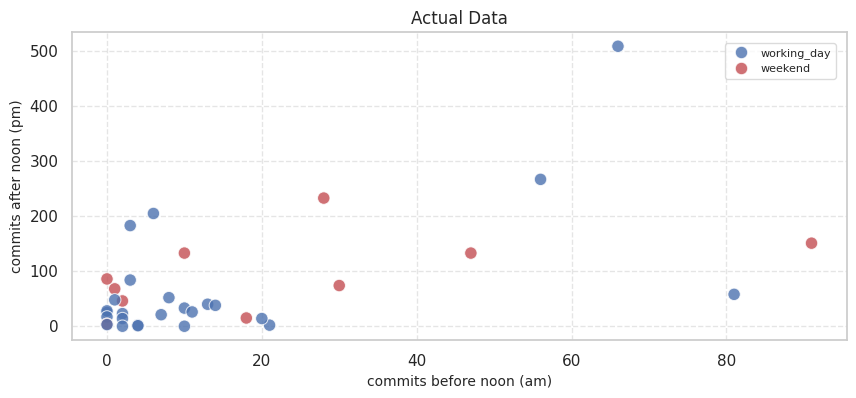

In [106]:
def draw_plot(name, column):
    plt.figure(figsize=(10, 4))
    sns.scatterplot(
        data=df,
        x="am",
        y="pm",
        hue=column,
        palette={"working_day": "b", "weekend": "r"},
        alpha=0.8,
        s=80,
    )
    plt.xlabel("commits before noon (am)", fontsize=10)
    plt.ylabel("commits after noon (pm)", fontsize=10)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.title(name)
    plt.legend(
        fontsize=8,
        loc="upper right",
        borderaxespad=1,
        frameon=True,
        facecolor="white",
        edgecolor="lightgray",
    )
    plt.show()


draw_plot("Actual Data", "target")

- Посмотрев на график, как ты думаешь, будет ли легко классифицировать дни, имея только эти две характеристики? Напиши свой ответ в markdown-ячейке в конце этого раздела: "Да, просто" или "Нет, не просто".

Ответ: Нет, не просто

## 3. Логистическая регрессия

In [ ]:
X = df[["am", "pm"]]
y = (df["target"] == "weekend").astype(int)

- Обучи модель логистической регрессии на своих данных, используя `am` и `pm`; параметры: `random state=21`, `fit_intercept=False`.  

In [ ]:
model = LogisticRegression(random_state=21, fit_intercept=False)
model.fit(X, y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",False
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",21
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mult

- Сделай предсказания для каждого дня из набора данных и добавь их в датафрейм в столбец с именем `predict`.  

In [ ]:
y_pred = model.predict(X)

In [ ]:
df["predict"] = np.where(y_pred == 1, "weekend", "working_day")
df.head(3)

,date,am,pm,target,predict
0,2020-04-17,21,2,working_day,weekend
1,2020-04-18,1,68,weekend,working_day
2,2020-04-19,18,15,weekend,working_day


- Сохрани датафрейм в файл в подпапке дня `data` под именем `am_pm.csv`.  

In [113]:
df.to_csv("../data/am_pm.csv", index=False)


- Построй ещё один график, как ранее, но теперь цвет точек должен определяться значениями из столбца `predict`. 

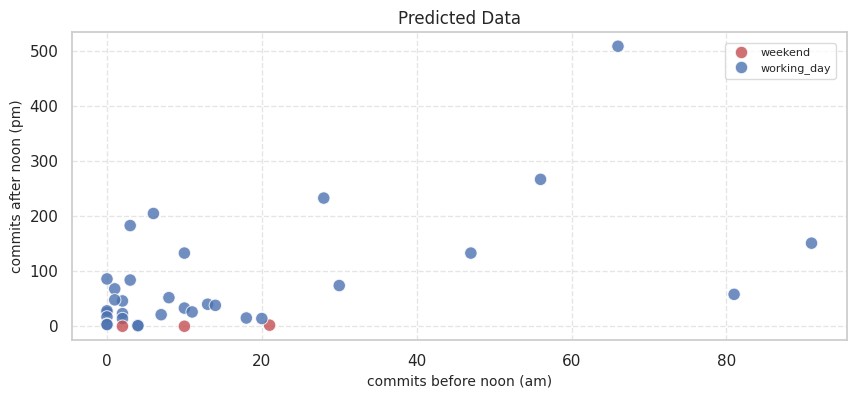

In [114]:
draw_plot(name="Predicted Data", column="predict")

- Посмотрев на график, как ты думаешь, сделала ли модель хорошие предсказания?

Нет, плохие.

## 4. Оценка

- Вычисли `accuracy` (точность) для своих предсказаний.  

In [115]:
model_accuracy = accuracy_score(df["target"], df["predict"])
print(model_accuracy)

0.6285714285714286


- Вычисли `accuracy` для наивного случая, когда каждое предсказание — это значение самого популярного класса дня.  

In [ ]:
naive_accuracy = df["target"].value_counts().max() / df.shape[0]
print(naive_accuracy)

0.7142857142857143


- Сравни значения точности и подумай, сделал ли классификатор хорошие предсказания? 

Нет, плохие.